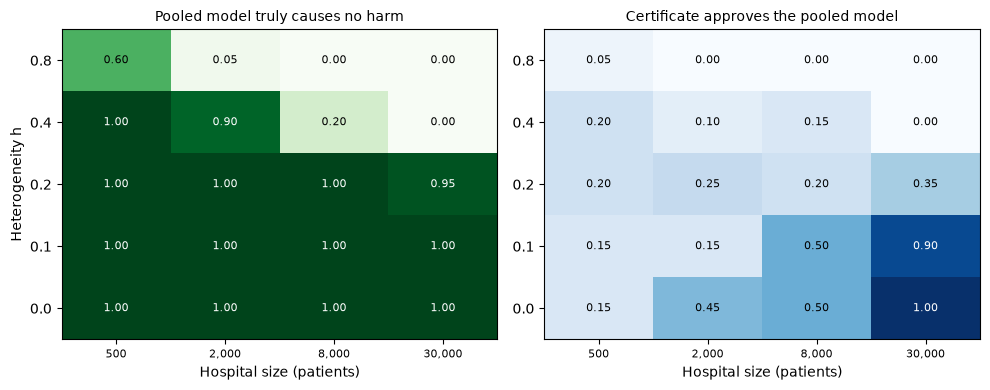

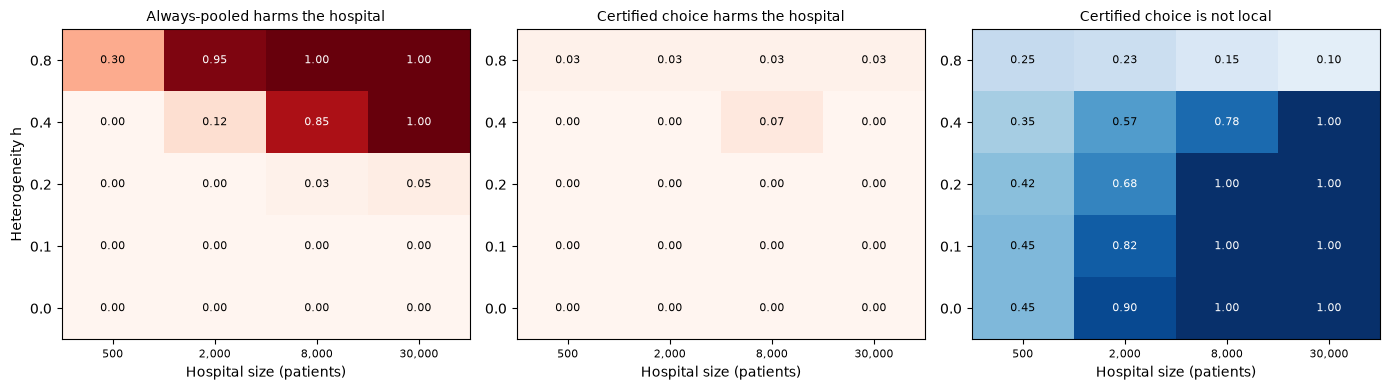

n                              500    2000   8000   30000
quantity                  h                              
truly_no_harm             0.0   1.00   1.00   1.00   1.00
                          0.1   1.00   1.00   1.00   1.00
                          0.2   1.00   1.00   1.00   0.95
                          0.4   1.00   0.90   0.20   0.00
                          0.8   0.60   0.05   0.00   0.00
certified                 0.0   0.15   0.45   0.50   1.00
                          0.1   0.15   0.15   0.50   0.90
                          0.2   0.20   0.25   0.20   0.35
                          0.4   0.20   0.10   0.15   0.00
                          0.8   0.05   0.00   0.00   0.00
pooled_harmed             0.0   0.00   0.00   0.00   0.00
                          0.1   0.00   0.00   0.00   0.00
                          0.2   0.00   0.00   0.02   0.05
                          0.4   0.00   0.12   0.85   1.00
                          0.8   0.30   0.95   1.00   1.00
certified_choi

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("../outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 10})
def save(name):
    plt.tight_layout(); plt.savefig(f"../outputs/figures/{name}.png", dpi=300); plt.savefig(f"../outputs/figures/{name}.pdf"); plt.show()

s1 = pd.read_csv("../outputs/tables/sim_phase_map_v1.csv")
s2 = pd.read_csv("../outputs/tables/sim_certified_selection_v1.csv")

def hm(ax, df, col, title, cmap, vmin=0, vmax=1, fmt="{:.2f}"):
    p = df.pivot_table(index="h", columns="n", values=col, aggfunc="mean").sort_index()
    ax.imshow(p.values, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(p.shape[1])); ax.set_xticklabels([f"{int(c):,}" for c in p.columns], fontsize=8)
    ax.set_yticks(range(p.shape[0])); ax.set_yticklabels(p.index)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="white" if (v - vmin) / (vmax - vmin + 1e-9) > 0.6 else "black")
    ax.set_xlabel("Hospital size (patients)"); ax.set_title(title, fontsize=10)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
hm(ax[0], s1, "true_no_harm", "Pooled model truly causes no harm", "Greens")
hm(ax[1], s1, "certified", "Certificate approves the pooled model", "Blues")
ax[0].set_ylabel("Heterogeneity h")
save("fig9_phase_map")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
hm(ax[0], s2, "pooled_harmed", "Always-pooled harms the hospital", "Reds")
hm(ax[1], s2, "selected_harmed", "Certified choice harms the hospital", "Reds")
hm(ax[2], s2, "nonlocal", "Certified choice is not local", "Blues")
ax[0].set_ylabel("Heterogeneity h")
save("fig10_simulation_certified")

T15 = pd.concat({
    "truly_no_harm": s1.pivot_table(index="h", columns="n", values="true_no_harm"),
    "certified": s1.pivot_table(index="h", columns="n", values="certified"),
    "pooled_harmed": s2.pivot_table(index="h", columns="n", values="pooled_harmed"),
    "certified_choice_harmed": s2.pivot_table(index="h", columns="n", values="selected_harmed"),
    "certified_choice_nonlocal": s2.pivot_table(index="h", columns="n", values="nonlocal"),
    "gain_certified_x1000": s2.pivot_table(index="h", columns="n", values="gain_sel_x1000"),
    "gain_pooled_x1000": s2.pivot_table(index="h", columns="n", values="gain_pooled_x1000")}, names=["quantity"])
T15.round(3).to_csv("../outputs/tables/T15_simulation_grid.csv")
print(T15.round(2).to_string())

200 repetitions; 12000 rows
max certified-choice harm rate: 0.0 | cells flagged (> 8.1%): 0 of 60
eps    delta
0.005  0.010    0.0
0.010  0.015    0.0
0.020  0.020    0.0
Name: harm_cert, dtype: float64


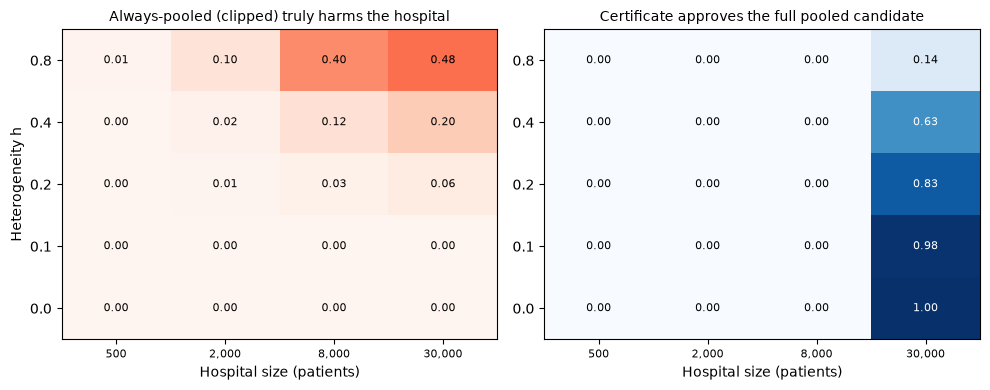

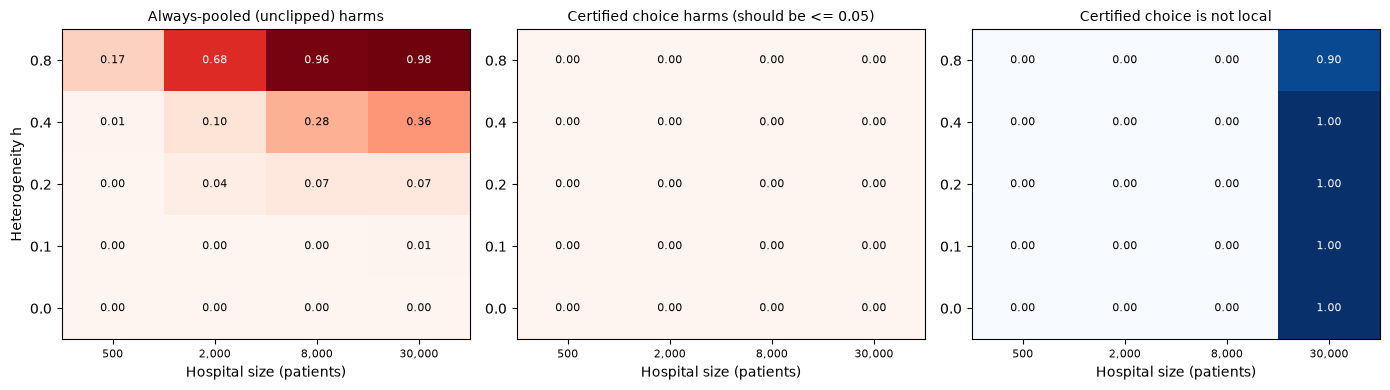

In [2]:
import glob
S = pd.concat([pd.read_csv(f) for f in glob.glob("../outputs/tables/sim_cert_*.csv")], ignore_index=True)
print(S.rep.nunique(), "repetitions;", len(S), "rows")
cell = S.groupby(["eps", "delta", "h", "n"]).agg(reps=("rep", "nunique"), harm_cert=("harm_certified", "mean"), nonlocal_=("nonlocal", "mean"),
        gain_x1000=("gain_certified", lambda s: 1000 * s.mean()), harm_pool_full=("harm_pool_full", "mean"),
        pool_clipped_truly_harmful=("harm_pool_clipped", "mean"), approved_pool=("approved_pool", "mean")).reset_index()
cell["flag"] = cell.harm_cert > 0.081
cell.round(3).to_csv("../outputs/tables/T15_simulation_grid.csv", index=False)
print("max certified-choice harm rate:", cell.harm_cert.max().round(3), "| cells flagged (> 8.1%):", int(cell.flag.sum()), "of", len(cell))
print(cell.groupby(["eps", "delta"]).harm_cert.max().round(3))

def hm(ax, d, col, title, cmap, vmax=1.0):
    p = d.pivot_table(index="h", columns="n", values=col).sort_index()
    ax.imshow(p.values, origin="lower", cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(p.shape[1])); ax.set_xticklabels([f"{int(c):,}" for c in p.columns], fontsize=8)
    ax.set_yticks(range(p.shape[0])); ax.set_yticklabels(p.index)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v / vmax > 0.6 else "black")
    ax.set_xlabel("Hospital size (patients)"); ax.set_title(title, fontsize=10)

hd = cell[(cell.eps == 0.01) & (cell.delta == 0.015)]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
hm(ax[0], hd, "pool_clipped_truly_harmful", "Always-pooled (clipped) truly harms the hospital", "Reds")
hm(ax[1], hd, "approved_pool", "Certificate approves the full pooled candidate", "Blues"); ax[0].set_ylabel("Heterogeneity h")
save("fig9_phase_map")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
hm(ax[0], hd, "harm_pool_full", "Always-pooled (unclipped) harms", "Reds")
hm(ax[1], hd, "harm_cert", "Certified choice harms (should be <= 0.05)", "Reds", vmax=0.2)
hm(ax[2], hd, "nonlocal_", "Certified choice is not local", "Blues"); ax[0].set_ylabel("Heterogeneity h")
save("fig10_simulation_certified")